# Data formats

In this notebook, you will have to read and write some data in particular formats : you will have to provide some python code or some answers to questions in a text format

Make sure you are running this notebook on IGE jupyterhub in the pangeo-notebook environment otherwise the necessary python libraries will not be found.

Tips : duplicate this notebook in a draft version in which you can try and check the outputs with some prints and plots before submitting the final version to Github/Gitlab


Note : 
Some data files are provided in this repository : /workdir/ping/alberta/ORL26-27/lab02, copy them here in a ```data``` subdirectory and make sure that these data files will not be uploaded to Github/Gitlab by adding this line in your .gitignore :
```labs/02_data-management/data```

You can also prevent the upload of other files, like png files for instance by adding the line :
```labs/02_data-management/*png```

## Part 1 : Text files



Let's have a look first at the precipitation.txt file, using read function print the 4th line of the file

In [2]:
with open("data/precipitation.txt", "r+") as f:
    for line in f:
        print(line,end='')              

-88.92773  0  1.091546e-06
-87.5387  1.40625   1.054535e-06
-86.14147  2.8125  1.078923e-06
-84.74239  4.21875  1.016285e-06
-83.3426  5.625  1.000412e-06
-80.54214  8.4375  1.016951e-06
-79.14171  9.84375  1.066608e-06
-77.7412  11.25  1.060027e-06
-76.34063  12.65625  1.044903e-06
-74.94003  14.0625  1.051413e-06

In [3]:
with open('data/precipitation.txt', 'r') as f:
    a = [line.strip() for line in f]
print(a)

['-88.92773  0  1.091546e-06', '-87.5387  1.40625   1.054535e-06', '-86.14147  2.8125  1.078923e-06', '-84.74239  4.21875  1.016285e-06', '-83.3426  5.625  1.000412e-06', '-80.54214  8.4375  1.016951e-06', '-79.14171  9.84375  1.066608e-06', '-77.7412  11.25  1.060027e-06', '-76.34063  12.65625  1.044903e-06', '-74.94003  14.0625  1.051413e-06']


In [12]:
print(a[3])

-84.74239  4.21875  1.016285e-06


Try to access the first element of the 4th line, what is happening ?

In [15]:
a[3][0]

'-'

Using numpy now, open the file and store the content in an array and print the first element of the 4th line of the file

In [19]:
import numpy as np
array = np.loadtxt('data/precipitation.txt')
print(array)

[[-8.892773e+01  0.000000e+00  1.091546e-06]
 [-8.753870e+01  1.406250e+00  1.054535e-06]
 [-8.614147e+01  2.812500e+00  1.078923e-06]
 [-8.474239e+01  4.218750e+00  1.016285e-06]
 [-8.334260e+01  5.625000e+00  1.000412e-06]
 [-8.054214e+01  8.437500e+00  1.016951e-06]
 [-7.914171e+01  9.843750e+00  1.066608e-06]
 [-7.774120e+01  1.125000e+01  1.060027e-06]
 [-7.634063e+01  1.265625e+01  1.044903e-06]
 [-7.494003e+01  1.406250e+01  1.051413e-06]]


In [14]:
print(array[3])

[-8.474239e+01  4.218750e+00  1.016285e-06]


In [16]:
array[3][0]

np.float64(-84.74239)

Create a new txt file with precipitation in g/m2/s instead of kg/m2/s

In [18]:
new_array=np.copy(array)

In [22]:
new_array[:,2]=1000*new_array[:,2]

In [23]:
print(new_array)

[[-8.892773e+01  0.000000e+00  1.091546e-03]
 [-8.753870e+01  1.406250e+00  1.054535e-03]
 [-8.614147e+01  2.812500e+00  1.078923e-03]
 [-8.474239e+01  4.218750e+00  1.016285e-03]
 [-8.334260e+01  5.625000e+00  1.000412e-03]
 [-8.054214e+01  8.437500e+00  1.016951e-03]
 [-7.914171e+01  9.843750e+00  1.066608e-03]
 [-7.774120e+01  1.125000e+01  1.060027e-03]
 [-7.634063e+01  1.265625e+01  1.044903e-03]
 [-7.494003e+01  1.406250e+01  1.051413e-03]]


In [24]:
np.savetxt('data/newprecip.txt', new_array)

Do you think this data format allows to make our data FAIR and why ?

##  Part 2 Tabular data

Now we are going to have a look at precipitation.csv file which is a CSV file

Using python built-in csv reader, print the 4th line of the file

In [28]:
import csv

with open('data/precipitation.csv', mode='r') as f:
    a = [line for line in csv.reader(f)]
print(a)        

[['Lat', ' Lon', ' Precip'], ['-88.92773', ' 0', ' 1.091546e-06'], ['-87.5387', ' 1.40625 ', ' 1.054535e-06'], ['-86.14147', ' 2.8125', ' 1.078923e-06'], ['-84.74239', ' 4.21875', ' 1.016285e-06'], ['-83.3426', ' 5.625', ' 1.000412e-06'], ['-80.54214', ' 8.4375', ' 1.016951e-06'], ['-79.14171', ' 9.84375', ' 1.066608e-06'], ['-77.7412', ' 11.25', ' 1.060027e-06'], ['-76.34063', ' 12.65625', ' 1.044903e-06'], ['-74.94003', ' 14.0625', ' 1.051413e-06']]


In [29]:
print(a[3])

['-86.14147', ' 2.8125', ' 1.078923e-06']


In [30]:
print(a[3][0])

-86.14147


Now using pandas

In [1]:
import pandas
df = pandas.read_csv('data/precipitation.csv')
pandas.set_option('display.float_format', '{:.4g}'.format)
print(df)

     Lat   Lon    Precip
0 -88.93     0 1.092e-06
1 -87.54 1.406 1.055e-06
2 -86.14 2.812 1.079e-06
3 -84.74 4.219 1.016e-06
4 -83.34 5.625     1e-06
5 -80.54 8.438 1.017e-06
6 -79.14 9.844 1.067e-06
7 -77.74 11.25  1.06e-06
8 -76.34 12.66 1.045e-06
9 -74.94 14.06 1.051e-06


In [2]:
df.columns

Index(['Lat', 'Lon', 'Precip'], dtype='object')

In [4]:
df.index

RangeIndex(start=0, stop=10, step=1)

In [13]:
df.loc[3]["Precip"]

np.float64(1.016285e-06)

Add a new column to the DataFrame with precip in g/m2/s and save it to a new csv file

In [14]:
df["Precip in g"]=1000*df["Precip"]
print(df)

     Lat   Lon    Precip  Precip in g
0 -88.93     0 1.092e-06     0.001092
1 -87.54 1.406 1.055e-06     0.001055
2 -86.14 2.812 1.079e-06     0.001079
3 -84.74 4.219 1.016e-06     0.001016
4 -83.34 5.625     1e-06        0.001
5 -80.54 8.438 1.017e-06     0.001017
6 -79.14 9.844 1.067e-06     0.001067
7 -77.74 11.25  1.06e-06      0.00106
8 -76.34 12.66 1.045e-06     0.001045
9 -74.94 14.06 1.051e-06     0.001051


In [15]:
df.to_csv("data/new_precipitation.csv")

How can you make this csv file more FAIR ?

## Part 3 Spatial data

Now we are going to work with the netcdf file sresa1b_ncar_ccsm3-example.nc

In [3]:
from netCDF4 import Dataset
nc_f = 'data/sresa1b_ncar_ccsm3-example.nc'  # Your filename
nc_fid = Dataset(nc_f, 'r')  # Dataset is the class behavior to open the file
                             # and create an instance of the ncCDF4 class
print(nc_fid)
nc_fid.close()

<class 'netCDF4.Dataset'>
root group (NETCDF3_CLASSIC data model, file format NETCDF3):
    CVS_Id: $Id$
    creation_date: 
    prg_ID: Source file unknown Version unknown Date unknown
    cmd_ln: bds -x 256 -y 128 -m 23 -o /data/zender/data/dst_T85.nc
    history: Tue Oct 25 15:08:51 2005: ncks -O -x -v va -m sresa1b_ncar_ccsm3_0_run1_200001.nc sresa1b_ncar_ccsm3_0_run1_200001.nc
Tue Oct 25 15:07:21 2005: ncks -d time,0 sresa1b_ncar_ccsm3_0_run1_200001_201912.nc sresa1b_ncar_ccsm3_0_run1_200001.nc
Tue Oct 25 13:29:43 2005: ncks -d time,0,239 sresa1b_ncar_ccsm3_0_run1_200001_209912.nc /var/www/html/tmp/sresa1b_ncar_ccsm3_0_run1_200001_201912.nc
Thu Oct 20 10:47:50 2005: ncks -A -v va /data/brownmc/sresa1b/atm/mo/va/ncar_ccsm3_0/run1/sresa1b_ncar_ccsm3_0_run1_va_200001_209912.nc /data/brownmc/sresa1b/atm/mo/tas/ncar_ccsm3_0/run1/sresa1b_ncar_ccsm3_0_run1_200001_209912.nc
Wed Oct 19 14:55:04 2005: ncks -F -d time,01,1200 /data/brownmc/sresa1b/atm/mo/va/ncar_ccsm3_0/run1/sresa1b_ncar_ccs

In [5]:
import xarray as xr
ds = xr.open_dataset('data/sresa1b_ncar_ccsm3-example.nc')
ds

Warning 3: Cannot find gdalvrt.xsd (GDAL_DATA is not defined)


<xarray.Dataset> Size: 3MB
Dimensions:    (lat: 128, lon: 256, bnds: 2, time: 1, plev: 17)
Coordinates:
  * lat        (lat) float32 512B -88.93 -87.54 -86.14 ... 86.14 87.54 88.93
  * lon        (lon) float32 1kB 0.0 1.406 2.812 4.219 ... 355.8 357.2 358.6
  * time       (time) object 8B 2000-05-16 12:00:00
  * plev       (plev) float64 136B 1e+05 9.25e+04 8.5e+04 ... 3e+03 2e+03 1e+03
Dimensions without coordinates: bnds
Data variables:
    area       (lat, lon) float32 131kB ...
    lat_bnds   (lat, bnds) float64 2kB ...
    lon_bnds   (lon, bnds) float64 4kB ...
    msk_rgn    (lat, lon) int32 131kB ...
    pr         (time, lat, lon) float32 131kB ...
    tas        (time, lat, lon) float32 131kB ...
    time_bnds  (time, bnds) object 16B ...
    ua         (time, plev, lat, lon) float32 2MB ...
Attributes: (12/18)
    CVS_Id:              $Id$
    creation_date:       
    prg_ID:              Source file unknown Version unknown Date unknown
    cmd_ln:              bds -x 256 -y 128 -m 23 -o /data/zender/data/dst_T85.nc
    history:             Tue Oct 25 15:08:51 2005: ncks -O -x -v va -m sresa1...
    table_id:            Table A1
    ...                  ...
    references:          Collins, W.D., et al., 2005:\n The Community Climate...
    acknowledgment:       Any use of CCSM data should acknowledge the contrib...
    realization:         1
    experiment_id:       720 ppm stabilization experiment (SRESA1B)
    comment:             This simulation was initiated from year 2000 of \n C...
    model_name_english:  NCAR CCSM

In [8]:
ds.ua.sel(lat=-70.73806, lon=355.78125, plev=10000.).values

array([16.889812], dtype=float32)

In [12]:
ds.ua.sel(lat=slice(-80,-70), lon=slice(350,360), plev=10000.)

array([[[ 8.336086 ,  8.2480135,  8.1665125,  8.091057 ,  8.021192 ,
          7.9566   ,  7.8971725],
        [ 9.707652 ,  9.625149 ,  9.551393 ,  9.485569 ,  9.426588 ,
          9.373276 ,  9.324634 ],
        [11.107362 , 11.019059 , 10.941959 , 10.876053 , 10.82051  ,
         10.77382  , 10.734155 ],
        [12.580085 , 12.485128 , 12.400572 , 12.327786 , 12.2673855,
         12.219107 , 12.181957 ],
        [14.131367 , 14.032093 , 13.943717 , 13.867747 , 13.804534 ,
         13.753571 , 13.713895 ],
        [15.688597 , 15.576358 , 15.481297 , 15.40431  , 15.34304  ,
         15.293179 , 15.250164 ],
        [17.283195 , 17.155712 , 17.048248 , 16.96102  , 16.889812 ,
         16.827839 , 16.7684   ]]], dtype=float32)

In [10]:
ds.ua.interp(lat=-70, lon=355, plev=10000.).values

array([17.85639557])

In [15]:
ds.pr.min(dim=["lat","lon"]).values

array([2.4459642e-26], dtype=float32)

In [16]:
ds.pr.max(dim=["lat","lon"]).values

array([0.00030686], dtype=float32)

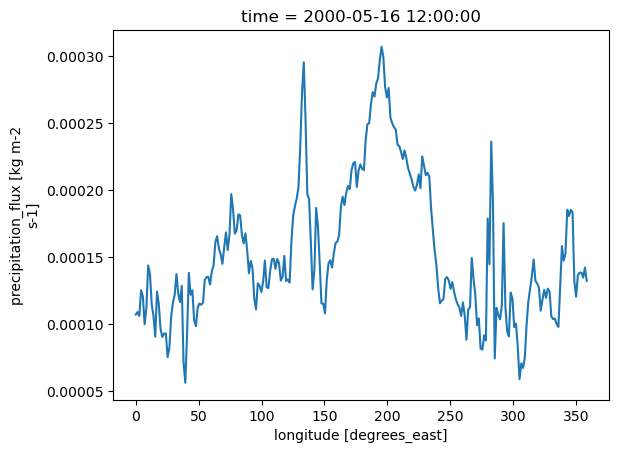

In [18]:
ds.pr.max(dim="lat").plot()

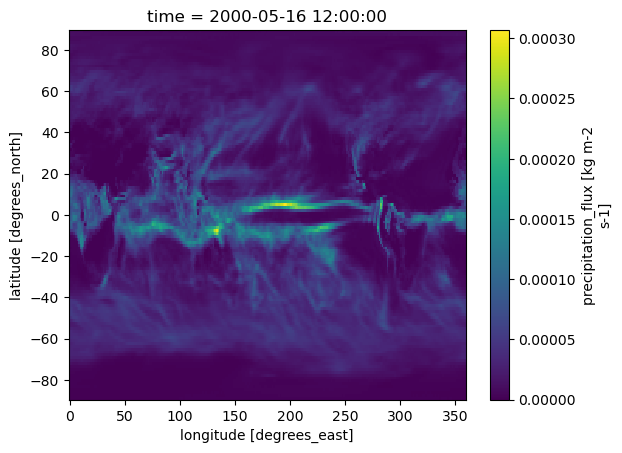

In [19]:
ds.pr.plot()

Let's create our own netcdf file with xarray, following the CF conventions

In [20]:
from datetime import timedelta

import numpy as np
import pandas as pd
import xarray as xr

generate a random numpy array

In [21]:
data = 283 + 5 * np.random.randn(5, 3, 4)
data

array([[[292.28160654, 289.20034287, 285.76214098, 278.32469404],
        [271.95172774, 289.84157316, 281.97391559, 283.35217555],
        [287.80023045, 287.36996109, 279.93473805, 281.12761776]],

       [[282.74901598, 286.32476166, 290.47349677, 293.7834552 ],
        [287.93586773, 283.69707099, 278.43687771, 286.55768503],
        [282.53244284, 284.56056264, 279.59478747, 283.02077952]],

       [[277.08292944, 279.67062372, 285.29827971, 287.29082951],
        [275.66972347, 293.71581657, 276.72014145, 274.51403097],
        [287.69597144, 287.13162252, 282.22733612, 280.9128498 ]],

       [[284.9022596 , 288.32802784, 279.54437616, 285.13996216],
        [273.40787355, 273.37494822, 286.35666278, 281.47155664],
        [276.84094583, 282.43879706, 285.69807899, 277.1662329 ]],

       [[281.59307208, 299.86753239, 275.55681346, 284.00928552],
        [290.25821865, 278.06757125, 275.40870403, 278.1980966 ],
        [277.94046126, 292.88937031, 281.82971299, 285.10101194]]])

In [24]:
times = pd.date_range('2018-01-01', periods=5)
times

DatetimeIndex(['2018-01-01', '2018-01-02', '2018-01-03', '2018-01-04',
               '2018-01-05'],
              dtype='datetime64[ns]', freq='D')

In [25]:
lons = np.linspace(-120, -60, 4)
lats = np.linspace(25, 55, 3)

In [26]:
temp = xr.DataArray(data, coords=[times, lats, lons], dims=['time', 'lat', 'lon'])
temp

<xarray.DataArray (time: 5, lat: 3, lon: 4)> Size: 480B
array([[[292.28160654, 289.20034287, 285.76214098, 278.32469404],
        [271.95172774, 289.84157316, 281.97391559, 283.35217555],
        [287.80023045, 287.36996109, 279.93473805, 281.12761776]],

       [[282.74901598, 286.32476166, 290.47349677, 293.7834552 ],
        [287.93586773, 283.69707099, 278.43687771, 286.55768503],
        [282.53244284, 284.56056264, 279.59478747, 283.02077952]],

       [[277.08292944, 279.67062372, 285.29827971, 287.29082951],
        [275.66972347, 293.71581657, 276.72014145, 274.51403097],
        [287.69597144, 287.13162252, 282.22733612, 280.9128498 ]],

       [[284.9022596 , 288.32802784, 279.54437616, 285.13996216],
        [273.40787355, 273.37494822, 286.35666278, 281.47155664],
        [276.84094583, 282.43879706, 285.69807899, 277.1662329 ]],

       [[281.59307208, 299.86753239, 275.55681346, 284.00928552],
        [290.25821865, 278.06757125, 275.40870403, 278.1980966 ],
        [277.94046126, 292.88937031, 281.82971299, 285.10101194]]])
Coordinates:
  * time     (time) datetime64[ns] 40B 2018-01-01 2018-01-02 ... 2018-01-05
  * lat      (lat) float64 24B 25.0 40.0 55.0
  * lon      (lon) float64 32B -120.0 -100.0 -80.0 -60.0

In [27]:
temp.attrs['units'] = 'kelvin'
temp.attrs['standard_name'] = 'air_temperature'

temp

<xarray.DataArray (time: 5, lat: 3, lon: 4)> Size: 480B
array([[[292.28160654, 289.20034287, 285.76214098, 278.32469404],
        [271.95172774, 289.84157316, 281.97391559, 283.35217555],
        [287.80023045, 287.36996109, 279.93473805, 281.12761776]],

       [[282.74901598, 286.32476166, 290.47349677, 293.7834552 ],
        [287.93586773, 283.69707099, 278.43687771, 286.55768503],
        [282.53244284, 284.56056264, 279.59478747, 283.02077952]],

       [[277.08292944, 279.67062372, 285.29827971, 287.29082951],
        [275.66972347, 293.71581657, 276.72014145, 274.51403097],
        [287.69597144, 287.13162252, 282.22733612, 280.9128498 ]],

       [[284.9022596 , 288.32802784, 279.54437616, 285.13996216],
        [273.40787355, 273.37494822, 286.35666278, 281.47155664],
        [276.84094583, 282.43879706, 285.69807899, 277.1662329 ]],

       [[281.59307208, 299.86753239, 275.55681346, 284.00928552],
        [290.25821865, 278.06757125, 275.40870403, 278.1980966 ],
        [277.94046126, 292.88937031, 281.82971299, 285.10101194]]])
Coordinates:
  * time     (time) datetime64[ns] 40B 2018-01-01 2018-01-02 ... 2018-01-05
  * lat      (lat) float64 24B 25.0 40.0 55.0
  * lon      (lon) float64 32B -120.0 -100.0 -80.0 -60.0
Attributes:
    units:          kelvin
    standard_name:  air_temperature

In [28]:
pressure_data = 1000.0 + 5 * np.random.randn(5, 3, 4)
pressure = xr.DataArray(
    pressure_data, coords=[times, lats, lons], dims=['time', 'lat', 'lon']
)
pressure.attrs['units'] = 'hPa'
pressure.attrs['standard_name'] = 'air_pressure'

pressure

<xarray.DataArray (time: 5, lat: 3, lon: 4)> Size: 480B
array([[[ 997.5318203 , 1008.28937382, 1002.89277808,  997.13643549],
        [1000.21389205, 1002.15793867,  993.56139598, 1001.18373835],
        [1002.9928992 ,  985.37669317,  999.26182515, 1003.8208518 ]],

       [[ 999.23617719, 1002.43673235, 1003.01087235,  994.80802835],
        [1002.17526914, 1007.29096183,  996.21295372,  997.99200678],
        [ 996.96556599, 1000.29328549, 1000.7370836 ,  996.79555249]],

       [[1000.68262723,  998.74765836, 1005.74420284,  997.42011469],
        [1003.18026469,  988.44914947, 1006.08405252,  996.71051782],
        [1005.98465232, 1005.12225403,  994.06078091,  994.01896499]],

       [[1005.38051761, 1005.3067515 , 1007.84423734,  995.88235699],
        [1004.74619622, 1010.42063921, 1001.24848615,  998.31928113],
        [ 997.43012362,  991.81359129, 1000.12975789, 1002.15437734]],

       [[ 997.38358214,  999.19650625, 1004.53751585, 1002.68976142],
        [ 998.42880519,  999.61888145,  996.31948112, 1002.12632716],
        [ 989.71560207, 1006.36330139,  998.86898939,  996.15581297]]])
Coordinates:
  * time     (time) datetime64[ns] 40B 2018-01-01 2018-01-02 ... 2018-01-05
  * lat      (lat) float64 24B 25.0 40.0 55.0
  * lon      (lon) float64 32B -120.0 -100.0 -80.0 -60.0
Attributes:
    units:          hPa
    standard_name:  air_pressure

In [29]:
ds = xr.Dataset(data_vars={'Temperature': temp, 'Pressure': pressure})
ds

<xarray.Dataset> Size: 1kB
Dimensions:      (time: 5, lat: 3, lon: 4)
Coordinates:
  * time         (time) datetime64[ns] 40B 2018-01-01 2018-01-02 ... 2018-01-05
  * lat          (lat) float64 24B 25.0 40.0 55.0
  * lon          (lon) float64 32B -120.0 -100.0 -80.0 -60.0
Data variables:
    Temperature  (time, lat, lon) float64 480B 292.3 289.2 285.8 ... 281.8 285.1
    Pressure     (time, lat, lon) float64 480B 997.5 1.008e+03 ... 998.9 996.2

In [32]:
ds.lat.attrs['units'] = 'degree_north'
ds.lat.attrs['standard_name'] = 'latitude'

ds.lat

<xarray.DataArray 'lat' (lat: 3)> Size: 24B
array([25., 40., 55.])
Coordinates:
  * lat      (lat) float64 24B 25.0 40.0 55.0
Attributes:
    units:          degree_north
    standard_name:  latitude

In [33]:
ds.lon.attrs['units'] = 'degree_east'
ds.lon.attrs['standard_name'] = 'longitude'

ds.lon

<xarray.DataArray 'lon' (lon: 4)> Size: 32B
array([-120., -100.,  -80.,  -60.])
Coordinates:
  * lon      (lon) float64 32B -120.0 -100.0 -80.0 -60.0
Attributes:
    units:          degree_east
    standard_name:  longitude

In [34]:
ds.to_netcdf("data/random_temp_press.nc")

check with ncdump in a terminal the content of the newly created file (load the pangeo-notebook environment with ```micromamba activate pangeo-notebook```